5 dòng đầu tiên:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


Kích thước dữ liệu: 418 dòng, 12 cột

--- Thống kê mô tả ---


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200



--- Số lượng giá trị thiếu ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


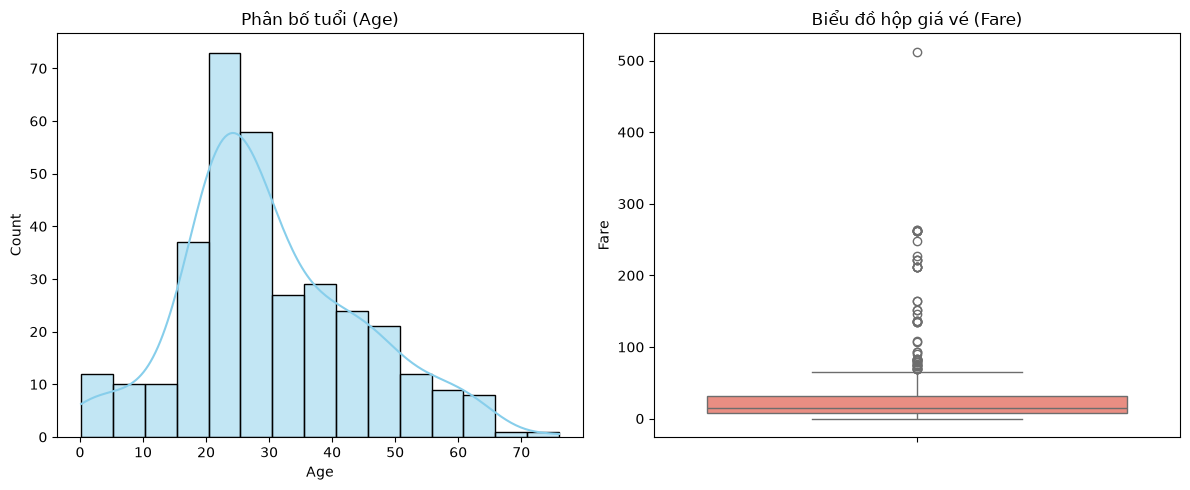

Đã lưu thành công file làm sạch tại: D:\DataMining_Practice1\output\titanic_clean.csv


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Định nghĩa đường dẫn tương đối theo cấu trúc thư mục
BASE_DIR = Path().resolve().parent
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "output"

# Tạo thư mục output nếu chưa có
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Nạp dữ liệu
df_titanic = pd.read_csv(DATA_DIR / "titanic.csv")
print("5 dòng đầu tiên:")
display(df_titanic.head())

# 2. Số dòng, số cột
print(f"Kích thước dữ liệu: {df_titanic.shape[0]} dòng, {df_titanic.shape[1]} cột")

# 3. Thống kê mô tả và đếm giá trị thiếu
print("\n--- Thống kê mô tả ---")
display(df_titanic.describe())

print("\n--- Số lượng giá trị thiếu ---")
print(df_titanic.isnull().sum())

# 4. Trực quan hóa dữ liệu và lưu biểu đồ vào thư mục output
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_titanic['Age'].dropna(), kde=True, color='skyblue')
plt.title('Phân bố tuổi (Age)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_titanic['Fare'], color='salmon')
plt.title('Biểu đồ hộp giá vé (Fare)')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "titanic_plots.png", dpi=300)
plt.show()

# 5. Điền giá trị trung vị cho Age
median_age = df_titanic['Age'].median()
df_titanic['Age'] = df_titanic['Age'].fillna(median_age)

# 6. Chuẩn hóa các cột Age và Fare (StandardScaler)
df_titanic['Fare'] = df_titanic['Fare'].fillna(df_titanic['Fare'].median())
scaler = StandardScaler()
df_titanic[['Age_scaled', 'Fare_scaled']] = scaler.fit_transform(df_titanic[['Age', 'Fare']])

# 7. Mã hóa cột Sex và Embarked
df_titanic['Embarked'] = df_titanic['Embarked'].fillna(df_titanic['Embarked'].mode()[0])
label_encoder = LabelEncoder()
df_titanic['Sex_encoded'] = label_encoder.fit_transform(df_titanic['Sex'])
df_titanic['Embarked_encoded'] = label_encoder.fit_transform(df_titanic['Embarked'])

# 8. Lưu kết quả làm sạch vào thư mục output/
clean_file_path = OUTPUT_DIR / "titanic_clean.csv"
df_titanic.to_csv(clean_file_path, index=False)
print(f"Đã lưu thành công file làm sạch tại: {clean_file_path}")